# UCS420 Lab Assignment 7 : NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170271          # <-- your full roll number
NAME = "Himantveer Kaur"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170271   Name: Himantveer Kaur   Fingerprint: CE986B07   Tickets: 13

Ticket_ID                                                                                        Ticket_Text
      T01            I couldn't connect to the lms when I use mobile hotspot. The same problem occurs again.
      T02                                                               Python 3.12 was installed yesterday.
      T03                                            The student portal is not working. It worked yesterday.
      T04                            I can't open the projector while uploading the file. Please resolve it.
      T05                                                        The VPN is not working. Can you check this?
      T06                               I reinstalled the student portal since yesterday. Please resolve it.
      T07                                                                 Dr. Rao's lab PC (No. 14) is down.
      T08                                

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
# run the official pipeline on every ticket and keep the results in a dictionary
results = {}
for i in range(len(df)):
    results[df.loc[i, "Ticket_ID"]] = process_ticket(df.loc[i, "Ticket_Text"])

# one row per ticket with the counts asked in the question
rows = []
for tid in results:
    r = results[tid]
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })
table1 = pd.DataFrame(rows)

# total row for the count columns
total = table1.drop(columns="Ticket_ID").sum()
total["Ticket_ID"] = "TOTAL"
table1 = pd.concat([table1, pd.DataFrame([total])], ignore_index=True)
print(table1.to_string(index=False))

# details of one selected ticket (using the first focus ticket)
sel = FOCUS[0]
r = results[sel]
print("\nSelected ticket:", sel)
print("Text        :", df.loc[df["Ticket_ID"] == sel, "Ticket_Text"].values[0])
print("Tokens      :", r["tokens"])
print("Punctuation :", r["punct"])
print("Stopwords   :", r["stops"])
print("Final tokens:", r["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords  Unique_Tokens  Final_Tokens
      T01          2      19            2          8             16             9
      T02          1       6            1          1              6             4
      T03          2      11            2          4             10             5
      T04          2      15            2          5             13             8
      T05          2      11            2          6             11             3
      T06          2      12            2          3             11             7
      T07          2      13            4          3             12             6
      T08          2      11            2          3              9             6
      T09          2      14            2          3             13             9
      T10          2      21            2          9             19            10
      T11          1      10            2          4              9             4
      T12       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens that are not real words are `n't`, `ca`, `'s`, `dr.` and `university.edu`.
- `n't` appears 4 times (T01, T04, T10, T11). `word_tokenize` splits contractions into two parts, so *couldn't* becomes `could` + `n't`, *don't* becomes `do` + `n't`, and *doesn't* becomes `does` + `n't`. Only `could` survives the stopword filter, while `n't` is not in the stopword list so it stays.
- `ca` comes from *can't* (T04), which is split as `ca` + `n't`. Here `ca` is a leftover piece of "can".
- `'s` comes from the possessive in *Rao's* (T07), which is split as `rao` + `'s`.
- `dr.` (T07) keeps its full stop because the tokenizer treats it as an abbreviation, and since the token has letters it is not removed as punctuation.
- `university.edu` (T12) is left over when the email `helpdesk@university.edu` is broken at the `@` sign.

So all of these come from the tokenizer splitting contractions, possessives and emails, and the stopword / punctuation filters do not clean them.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# a word should not start or end in the middle of an email, url or hyphenated word,
# so these small lookbehind / lookahead pieces check what is around the match
START = r"(?<![\w@./'-])"     # not preceded by a letter, @ . / ' or -
END = r"(?![\w@']|\.\w)"      # not followed by a letter, @ ' or a dot followed by a letter
WORD = r"[A-Za-z]+(?:[-'][A-Za-z]+)*"   # a word, may contain hyphens or apostrophes

long_pat = r"(?<![\w@./'])[A-Za-z]{6,}" + END      # words longer than 5 letters
num_pat = r"0x[0-9A-Fa-f]+|\d+(?:[.,]\d+)*"        # hex codes, integers, decimals, versions, 1,250
cap_pat = START + r"[A-Z][a-z]*(?:[-'][A-Za-z]+)*" + END          # capitalized words
vowel_pat = START + r"[AEIOUaeiou][A-Za-z]*(?:[-'][A-Za-z]+)*" + END  # words starting with a vowel

# patterns for re.sub
url_pat = r"(?:https?://|www\.)[\w-]+(?:\.[\w-]+)+(?:/[\w\-./?=&%]*\w)?"
email_pat = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
phone_pat = r"(?:\+\d{1,3}[\s-]?)?\d{3,5}[\s-]\d{3,5}(?:[\s-]\d{3,5})?"

def clean_text(text):
    text = re.sub(url_pat, "<URL>", text)
    text = re.sub(email_pat, "<EMAIL>", text)
    text = re.sub(phone_pat, "<PHONE>", text)
    return text

# ---- findall on the tickets
rows = []
for i in range(len(df)):
    t = df.loc[i, "Ticket_Text"]
    rows.append({
        "Ticket_ID": df.loc[i, "Ticket_ID"],
        "Long_words": re.findall(long_pat, t),
        "Numbers": re.findall(num_pat, t),
        "Capitalized": re.findall(cap_pat, t),
        "Vowel_words": re.findall(vowel_pat, t),
    })
q2_table = pd.DataFrame(rows)
for _, row in q2_table.iterrows():
    print(row["Ticket_ID"])
    print("   long words :", row["Long_words"])
    print("   numbers    :", row["Numbers"])
    print("   capitalized:", row["Capitalized"])
    print("   vowel words:", row["Vowel_words"])

# ---- re.sub on the tickets (only the changed ones are shown)
print("\nre.sub on tickets:")
for i in range(len(df)):
    t = df.loc[i, "Ticket_Text"]
    c = clean_text(t)
    if c != t:
        print(df.loc[i, "Ticket_ID"], "|", t)
        print("     ->", c)

# ---- same patterns on TEST_LINES
print("\nTEST_LINES")
for line in TEST_LINES:
    print("\nLine        :", line)
    print("long words  :", re.findall(long_pat, line))
    print("numbers     :", re.findall(num_pat, line))
    print("capitalized :", re.findall(cap_pat, line))
    print("vowel words :", re.findall(vowel_pat, line))
    print("cleaned     :", clean_text(line))

# how many capitalized words are just sentence starters?
total_cap = 0
for t in df["Ticket_Text"]:
    total_cap += len(re.findall(cap_pat, t))

starts = []
for tid in results:
    for s in results[tid]["sentences"]:
        m = re.match(cap_pat, s)      # does the sentence begin with a capitalized word?
        if m:
            starts.append(m.group())
print("\nCapitalized words in all tickets:", total_cap)
print("Capitalized words that start a sentence:", len(starts), starts)

T01
   long words : ['connect', 'mobile', 'hotspot', 'problem', 'occurs']
   numbers    : []
   capitalized: ['I', 'I', 'The']
   vowel words: ['I', 'I', 'use', 'occurs', 'again']
T02
   long words : ['Python', 'installed', 'yesterday']
   numbers    : ['3.12']
   capitalized: ['Python']
   vowel words: ['installed']
T03
   long words : ['student', 'portal', 'working', 'worked', 'yesterday']
   numbers    : []
   capitalized: ['The', 'It']
   vowel words: ['is', 'It']
T04
   long words : ['projector', 'uploading', 'Please', 'resolve']
   numbers    : []
   capitalized: ['I', 'Please']
   vowel words: ['I', 'open', 'uploading', 'it']
T05
   long words : ['working']
   numbers    : []
   capitalized: ['The', 'Can']
   vowel words: ['is']
T06
   long words : ['reinstalled', 'student', 'portal', 'yesterday', 'Please', 'resolve']
   numbers    : []
   capitalized: ['I', 'Please']
   vowel words: ['I', 'it']
T07
   long words : []
   numbers    : ['14']
   capitalized: ['Dr', "Rao's", 'No']


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* The tickets contain 27 capitalized words and 21 of them are the first word of a sentence. Five of these 21 are the pronoun *I*, and *Python* and *Dr* are capitalized anywhere, so that leaves 14 words (about half of the 27) that are capitalized only because they begin a sentence: *The* (4), *It* (2), *Please* (2), *This* (2), and *Can*, *Laptop*, *Email*, *E-mail* once each. The other 13 are *I* (6 times in total), *Python*, *Dr*, *Rao's*, *No* (from "No. 14") and *Wi-Fi* (3 times). So a capitalized-word pattern alone cannot find names, it also picks up every sentence starter.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer, word_tokenize
from collections import Counter

# the final pattern is built from small pieces joined with |
# order matters: the regex tries the pieces from left to right, so the long patterns come first
parts = [
    url_pat,                                  # https://lms.thapar.edu/help, www.thapar.edu/it
    email_pat,                                # helpdesk@university.edu
    phone_pat,                                # +91 98765 43210, 0175-239-3201
    r"0x[0-9A-Fa-f]+",                        # hex codes like 0x80070005
    r"\d+(?:[.,-]\d+)*",                      # 95.5, 2.0.1, 1,250, 1023-03-021
    r"(?:[A-Za-z]\.){2,}",                    # p.m., a.m.
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*",           # words with hyphens or apostrophes: Wi-Fi, isn't
]
PATTERN = "|".join(parts)
tokenizer = RegexpTokenizer(PATTERN)

def my_tokenize(text):
    return tokenizer.tokenize(text)

# ---- TEST_LINES
for line in TEST_LINES:
    print("my_tokenize  :", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))
    print()

# ---- tickets: compare with word_tokenize
# word_tokenize also returns punctuation tokens while my_tokenize drops them,
# so every ticket differs in the raw output. To see the real differences
# the punctuation tokens are removed from the word_tokenize output first.
diff_rows = []
raw_diff = 0
real_diff = 0
for i in range(len(df)):
    t = df.loc[i, "Ticket_Text"]
    mine = my_tokenize(t)
    nltk_all = word_tokenize(t)
    nltk_words = [x for x in nltk_all if not is_punct(x)]
    if mine != nltk_all:
        raw_diff += 1
    if mine != nltk_words:
        real_diff += 1
        diff_rows.append({
            "Ticket_ID": df.loc[i, "Ticket_ID"],
            "only_my_tokenize": [x for x in mine if x not in nltk_words],
            "only_word_tokenize": [x for x in nltk_words if x not in mine],
        })

print("Tickets that differ (raw output)           :", raw_diff, "of", len(df))
print("Tickets that differ (punctuation ignored)  :", real_diff, "of", len(df))
print()
print(pd.DataFrame(diff_rows).to_string(index=False))

# differences on the TEST_LINES (these cover urls and phone numbers which are not in the tickets)
print("\nDifferences on TEST_LINES (punctuation ignored)")
for k in range(len(TEST_LINES)):
    mine = my_tokenize(TEST_LINES[k])
    nltk_words = [x for x in word_tokenize(TEST_LINES[k]) if not is_punct(x)]
    print("Line", k + 1)
    print("   only my_tokenize  :", [x for x in mine if x not in nltk_words])
    print("   only word_tokenize:", [x for x in nltk_words if x not in mine])

my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

my_tokenize  : ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1,250']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

my_tokenize  : ['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p.m.', "didn't", 'work']
word_tokenize: ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']

Tickets that differ (raw output)           : 13 of 13
Tickets that differ (punctuation

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* All 13 tickets give a different raw output, because word_tokenize returns punctuation tokens (`.`, `,`) and my_tokenize drops them. After removing the punctuation tokens from the word_tokenize output, 6 of the 13 tickets (T01, T04, T07, T10, T11, T12) are still tokenized differently.

Differences found and why they happen:
1. **Contractions** (T01, T04, T10, T11 and `isn't`, `didn't` in TEST_LINES): word_tokenize follows the Penn Treebank rules and splits them, e.g. `couldn't` -> `could` + `n't`. My pattern allows an apostrophe inside a word, so `couldn't` stays as one token.
2. **Emails and URLs** (T12 and TEST_LINES): word_tokenize breaks `helpdesk@university.edu` into `helpdesk`, `@`, `university.edu` and `https://lms.thapar.edu/help` into `https`, `:`, `//lms.thapar.edu/help`. My pattern has the url and email parts first, so each one is a single token.
3. **Phone numbers** (TEST_LINES): `+91 98765 43210` is split on the spaces into `+91`, `98765`, `43210` by word_tokenize, while my phone pattern keeps it whole. (`0175-239-3201` stays whole in both because it has no spaces.)
4. **Dr. and Rao's** (T07): word_tokenize gives `Dr.`, `Rao`, `'s`, my_tokenize gives `Dr` and `Rao's` (it drops the full stop after Dr, but keeps the possessive together).
5. **Punctuation**: my_tokenize drops all punctuation, e.g. the `%` after `95.5` and the `;` are missing. This is the price of using only matches in RegexpTokenizer.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

# unique final tokens of all tickets
unique_final = sorted(set(w for tid in results for w in results[tid]["final"]))
print("Unique final tokens:", len(unique_final))

# POS tags: tagging is done on the full token list of each ticket so the tagger has context,
# then the tag of each word is stored (first time the word is seen)
pos_of = {}
for tid in results:
    for word, tag in nltk.pos_tag(results[tid]["tokens"]):
        if word not in pos_of:
            pos_of[word] = tag

# convert the Penn Treebank tag to the letter WordNet understands
def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("R"):
        return "r"
    else:
        return "n"

porter = PorterStemmer()
lancaster = LancasterStemmer()
# suffix rule: many verbs in the tickets end in -ing or -ed (working, uploading, asking,
# connected, installed, reinstalled), so these two endings are cut. min=4 keeps short words safe.
regexp = RegexpStemmer(r"ing$|ed$", min=4)
lemmatizer = WordNetLemmatizer()

rows = []
for w in unique_final:
    rows.append({
        "Word": w,
        "POS": pos_of[w],
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp.stem(w),
        "Lemma": lemmatizer.lemmatize(w, wordnet_pos(pos_of[w])),
    })
table4 = pd.DataFrame(rows)

# keep only the words where the outputs are not all the same as the word
different = table4[table4.apply(
    lambda r: len({r["Word"], r["Porter"], r["Lancaster"], r["Regexp"], r["Lemma"]}) > 1, axis=1)]
print("Words where the outputs differ:", len(different), "of", len(table4), "\n")
print(different.to_string(index=False))

# quick check of the regexp rule on a few words from the dataset
print("\nRegexp stemmer check:")
for w in ["working", "uploading", "connected", "installed", "running", "logged"]:
    print("  ", w, "->", regexp.stem(w))

Unique final tokens: 56


Words where the outputs differ: 31 of 56 

       Word POS    Porter Lancaster    Regexp     Lemma
    another  DT     anoth     anoth   another   another
     asking VBG       ask       ask       ask       ask
     campus  VB     campu      camp    campus    campus
    changed VBD     chang     chang     chang    change
   computer  NN    comput    comput  computer  computer
  connected VBN   connect   connect   connect   connect
       file  NN      file       fil      file      file
    getting VBG       get       get      gett       get
  installed VBN    instal    instal   install    instal
      keeps NNS      keep      keep     keeps      keep
        lms  NN        lm       lms       lms        lm
     logged VBD       log       log      logg       log
     mobile  JJ     mobil      mobl    mobile    mobile
     occurs VBZ     occur       occ    occurs     occur
       open  VB      open        op      open      open
     please  NN     pleas     pleas    please    please
     

**Observe:** Give one over-stemming and one under-stemming example from your table.

**Regexp suffix choice:** I used `ing$|ed$` with min=4. Many verbs in my tickets end with -ing or -ed (*working, uploading, asking, running* and *connected, installed, reinstalled, worked*), and cutting these endings gives the base word for most of them (working -> work, uploading -> upload, connected -> connect, installed -> install). The rule is weak when the last consonant is doubled (running -> runn, getting -> gett, logged -> logg) and it does nothing for words like *keeps* and *works*.

*Your answer:*
- **Over-stemming:** the Lancaster stemmer cuts too much, e.g. *portal* -> `port`, *projector* -> `project` and *student* -> `stud`. These stems look like different words, so unrelated words can end up together.
- **Under-stemming:** the Regexp stemmer leaves *works* -> `works` and *keeps* -> `keeps`, while *worked* and *working* become `work`. Words from the same family get different stems. Also *e-mail* (T10, T13) and *email* (T12) are the same word but none of the stemmers joins them.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Set  Total_Tokens  Unique_Tokens    TTR
 S1           164             88 0.5366
 S2           137             82 0.5985
 S3            81             56 0.6914
 S4            81             52 0.6420

Top 10 words of S1: [('.', 22), ('the', 10), ('i', 6), ('yesterday', 6), ('is', 6), ("n't", 4), ('it', 4), ('to', 3), ('when', 3), ('working', 3)]
Top 10 words of S3: [('yesterday', 6), ("n't", 4), ('working', 3), ('vpn', 3), ('since', 3), ('wi-fi', 3), ('student', 2), ('portal', 2), ('please', 2), ('resolve', 2)]


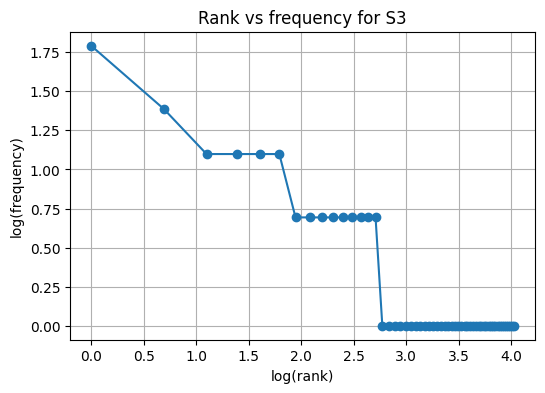

Top 5 bigrams of S1: [(('yesterday', '.'), 5), (('since', 'yesterday'), 3), (('the', 'student'), 2), (('student', 'portal'), 2), (('is', 'not'), 2)]
Top 5 bigrams of S3: [(('since', 'yesterday'), 3), (('student', 'portal'), 2), (('please', 'resolve'), 2), (('vpn', 'working'), 2), (('connected', 'campus'), 2)]


In [9]:
import matplotlib.pyplot as plt
import math

# the four token lists
S1 = [t for tid in results for t in results[tid]["tokens"]]                 # all tokens
S2 = [t for t in S1 if not is_punct(t)]                                      # no punctuation
S3 = [t for tid in results for t in results[tid]["final"]]                  # final tokens
S4 = [porter.stem(t) for t in S3]                                            # S3 after Porter

stats = []
for name, tokens in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    total_tokens = len(tokens)
    unique_tokens = len(set(tokens))
    stats.append({"Set": name, "Total_Tokens": total_tokens, "Unique_Tokens": unique_tokens,
                  "TTR": round(unique_tokens / total_tokens, 4)})
print(pd.DataFrame(stats).to_string(index=False))

# top 10 words
print("\nTop 10 words of S1:", Counter(S1).most_common(10))
print("Top 10 words of S3:", Counter(S3).most_common(10))

# log(rank) vs log(frequency) for S3
freq = Counter(S3).most_common()
ranks = [i + 1 for i in range(len(freq))]
counts = [f[1] for f in freq]
plt.figure(figsize=(6, 4))
plt.plot([math.log(r) for r in ranks], [math.log(c) for c in counts], "o-")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Rank vs frequency for S3")
plt.grid(True)
plt.show()

# top 5 bigrams: counted inside each ticket so no bigram crosses from one ticket to the next
def top_bigrams(key, n=5):
    counter = Counter()
    for tid in results:
        counter.update(nltk.bigrams(results[tid][key]))
    return counter.most_common(n)

print("Top 5 bigrams of S1:", top_bigrams("tokens"))
print("Top 5 bigrams of S3:", top_bigrams("final"))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR = unique tokens / total tokens. In my data it goes 0.5366 (S1) -> 0.5985 (S2) -> 0.6914 (S3) -> 0.6420 (S4).
- S1 -> S2: removing punctuation takes out 27 tokens but only 6 unique ones (the same `.` is repeated 22 times), so TTR goes up.
- S2 -> S3: removing stopwords takes out 56 tokens but only 26 unique ones, because words like *the*, *i* and *is* repeat a lot, so TTR goes up again.
- S3 -> S4: stemming does not change the 81 tokens but merges 4 word types (connect/connected, keep/keeps, work/worked/working/works), so unique tokens fall from 56 to 52 and TTR goes down.

The log-log plot of S3 is a short staircase because the corpus is tiny: *yesterday* appears 6 times and most words appear only once or twice, so it is not a clean straight line like Zipf's law.

---
## Q6. Interpretation

In [10]:
# small checks used in the answers below
for w in ["couldn't", "doesn't"]:
    print(w, "| word_tokenize:", word_tokenize(w), "| my_tokenize:", my_tokenize(w))
print()
for w in ["resolve", "slowly", "changed"]:
    print(w, "| Porter:", porter.stem(w), "| Lancaster:", lancaster.stem(w))
print()
for w in ["reinstalled", "changed", "logged"]:
    print(w, "| lemmatize without POS:", lemmatizer.lemmatize(w),
          "| with verb POS:", lemmatizer.lemmatize(w, "v"), "| Porter:", porter.stem(w))

couldn't | word_tokenize: ['could', "n't"] | my_tokenize: ["couldn't"]
doesn't | word_tokenize: ['does', "n't"] | my_tokenize: ["doesn't"]

resolve | Porter: resolv | Lancaster: resolv
slowly | Porter: slowli | Lancaster: slow
changed | Porter: chang | Lancaster: chang

reinstalled | lemmatize without POS: reinstalled | with verb POS: reinstall | Porter: reinstal
changed | lemmatize without POS: changed | with verb POS: change | Porter: chang
logged | lemmatize without POS: logged | with verb POS: log | Porter: log


**(a) Why does TTR change from S1 to S4?**
Removing punctuation and then stopwords removes many repeated tokens but fewer unique ones, so TTR rises from 0.5366 (S1) to 0.5985 (S2) and 0.6914 (S3). Stemming merges word forms (connect/connected, keep/keeps, work/worked/working/works), so unique tokens drop from 56 to 52 while the total stays 81, and TTR falls to 0.6420 (S4).

**(b) word_tokenize() vs my tokenizer**
In T01, `couldn't`: word_tokenize gives `could` and `n't` because it splits the negation from the verb, while my_tokenize gives `couldn't` as one token because my pattern allows an apostrophe inside a word. The email in T12 behaves the same way: word_tokenize gives `helpdesk`, `@`, `university.edu`, my_tokenize keeps `helpdesk@university.edu`.

**(c) Undesirable stemming result**
The Lancaster stemmer turns `portal` into `port`. In an IT-support ticket, "student portal" and a network "port" are different things, so the stem changes the meaning. Porter also gives non-words such as `resolv` (resolve) and `slowli` (slowly).

**(d) POS-aware lemmatization keeps the meaning better**
`changed` (T10) becomes `chang` with both Porter and Lancaster, which is not a word, but the lemmatizer with its verb tag gives `change`. Similarly `reinstalled`: without a POS tag WordNetLemmatizer leaves it as `reinstalled` (it assumes a noun), with the verb tag from nltk.pos_tag it becomes `reinstall`, while Porter gives `reinstal`.